# Train model


In [8]:
!uv pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.6/112.6 GB disk)


In [7]:
!unzip -o "/content/Team2_VN_traffic_sign_detect.v1i.yolov11 (1).zip" -d /content/Team2_VN_traffic_sign_detect.v1i.yolov11

Streaming output truncated to the last 5000 lines.
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/train/labels/IMG_4007-MOV_out0180_png_jpg.rf.81851ea0e312e0b272b5fe6b1764a6a2.txt  
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/train/labels/IMG_4007-MOV_out0180_png_jpg.rf.d97272122fee0ce33bb881de8455491e.txt  
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/train/labels/IMG_4007-MOV_out0181_png_jpg.rf.20e79ce3b34592510878edec8f62371a.txt  
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/train/labels/IMG_4007-MOV_out0185_png_jpg.rf.9f73106ee33769c199b57cf6f6ba1584.txt  
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/train/labels/IMG_4007-MOV_out0185_png_jpg.rf.e74a406225815e12a91bd94f225f6e63.txt  
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/train/labels/IMG_4007-MOV_out0185_png_jpg.rf.eb20ca4ab09944029a414d77b57d5dc5.txt  
  inflating: /content/Team2_VN_traffic_sign_detect.v1i.yolov11/trai

In [9]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.train(
    data="/content/Team2_VN_traffic_sign_detect.v1i.yolov11/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    lr0=0.001,
    optimizer="SGD",
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3,
    augment=True,
    patience=20
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Team2_VN_traffic_sign_detect.v1i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opse

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a3051fdd550>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.04

In [10]:
metrics = model.val()

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,939 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2313.0±644.4 MB/s, size: 76.4 KB)
val: Scanning /content/Team2_VN_traffic_sign_detect.v1i.yolov11/valid/labels.cache... 1600 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1600/1600 610.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 5.9it/s 16.8s
                   all       1600       2561      0.982      0.988      0.991      0.888
                     0        400        402      0.979      0.942      0.982      0.825
                     1         51         53      0.974          1      0.995      0.913
                    10         63         72      0.969          1      0.994      0.894
                    11        109        115      0.998          1      0.995      0.893
     

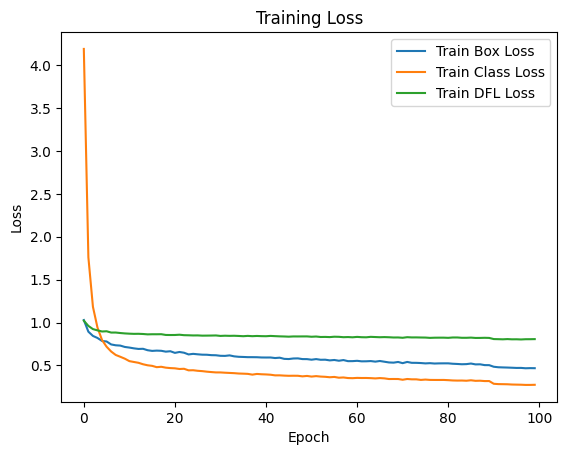

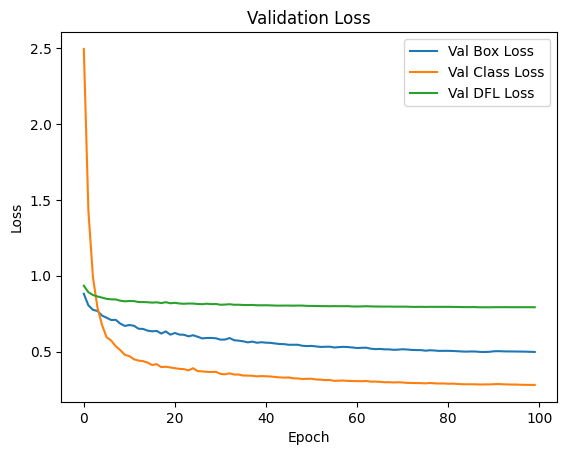

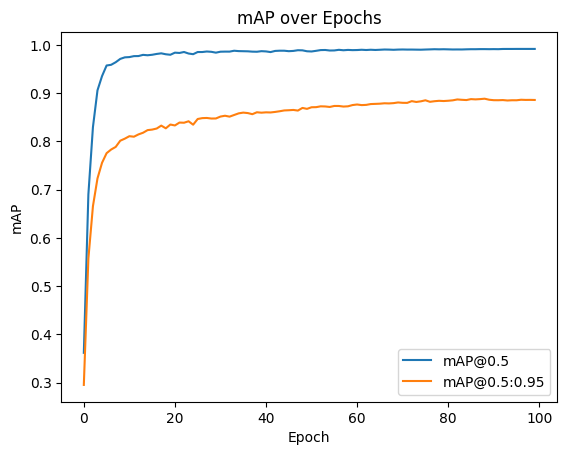

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/runs/detect/train2/results.csv")

#Train Loss
plt.plot(df["train/box_loss"], label="Train Box Loss")
plt.plot(df["train/cls_loss"], label="Train Class Loss")
plt.plot(df["train/dfl_loss"], label="Train DFL Loss")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Validation Loss
plt.plot(df["val/box_loss"], label="Val Box Loss")
plt.plot(df["val/cls_loss"], label="Val Class Loss")
plt.plot(df["val/dfl_loss"], label="Val DFL Loss")
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# mAP
plt.plot(df["metrics/mAP50(B)"], label="mAP@0.5")
plt.plot(df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
plt.title("mAP over Epochs")
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.legend()
plt.show()

# Predict

##ảnh

In [14]:
from ultralytics import YOLO

# Khởi tạo model từ file trọng số đã được train thành công hoặc file gốc
try:
    model = YOLO("/content/runs/detect/train/weights/best.pt")
except Exception:
    print("Chưa tìm thấy file train tốt nhất, đang sử dụng model mặc định hoặc model (1).pt")
    model = YOLO("/content/best (1).pt")

model.predict(
    source="/content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images",
    conf=0.01,
    save=True,
    save_txt=False
)


image 1/800 /content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images/942237_dataset-2024-05-10-08_36_16_in5-mp4_00299_jpg.rf.9d7f57d55cafc947c5e87701fd6522ee.jpg: 640x640 1 11, 1 15, 10.8ms
image 2/800 /content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images/942237_dataset-2024-05-10-08_36_16_in5-mp4_00313_jpg.rf.092fd1a8f40790b45c916dcc8cf4afa1.jpg: 640x640 1 11, 1 15, 14.5ms
image 3/800 /content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images/942237_dataset-2024-05-10-08_36_16_in5-mp4_00323_jpg.rf.75cee66d6f830c332e14485cd54c388f.jpg: 640x640 1 11, 1 15, 10.9ms
image 4/800 /content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images/942237_dataset-2024-05-10-08_36_16_in5-mp4_00369_jpg.rf.b6b4819ce8274b0220373d3aca237df9.jpg: 640x640 1 11, 1 15, 12.8ms
image 5/800 /content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images/942237_dataset-2024-05-10-08_36_16_in5-mp4_00375_jpg.rf.9b270007da3e9ef78a3b9c32bb20133d.jpg: 640x640 1 11, 1 15, 20.1ms
image 6/800 /content/Tea

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: '0', 1: '1', 2: '10', 3: '11', 4: '12', 5: '13', 6: '14', 7: '15', 8: '16', 9: '2', 10: '3', 11: '4', 12: '5', 13: '6', 14: '7', 15: '8', 16: '9'}
 obb: None
 orig_img: array([[[227, 219, 206],
         [237, 229, 216],
         [227, 219, 206],
         ...,
         [  0,   0,   0],
         [  1,   1,   1],
         [  5,   5,   5]],
 
        [[232, 224, 211],
         [221, 213, 200],
         [234, 226, 213],
         ...,
         [  1,   1,   1],
         [  3,   3,   3],
         [  4,   4,   4]],
 
        [[231, 223, 210],
         [255, 249, 236],
         [225, 217, 204],
         ...,
         [  2,   2,   2],
         [  1,   1,   1],
         [  0,   0,   0]],
 
        ...,
 
        [[114, 112, 112],
         [ 93,  91,  91],
         [102,  97,  98],
         ...,
         [ 89,  99, 106],
         [ 50, 

## Video thực tế



In [ ]:
from ultralytics import YOLO

model = YOLO("/content/best (1).pt")

model.predict(
    source="/content/Video_test3.mp4",
    save=True,
    conf=0.25
)

# Chỉnh bbox

In [ ]:
true_names = {
    0: "Cam ng.chieu",
    1: "C.xe may",
    2: "C.re trai",
    3: "C.quay dau",
    4: "C.dung/do",
    5: "C.do",
    6: "R.phai",
    7: "R.trai",
    8: "V.chuong ngai phai",
    9: "V.chuong ngai trai",
    10: "V.xuyen",
    11: "N.nguy hiem trai",
    12: "N.nguy hiem phai",
    13: "G.nhau den",
    14: "DS co rao chan",
    15: "Nguoi di bo",
    16: "Di cham"
}

In [ ]:
model_to_true = {
    0:0,
    1:1,
    2:10,
    3:11,
    4:12,
    5:13,
    6:14,
    7:15,
    8:16,
    9:2,
    10:3,
    11:4,
    12:5,
    13:6,
    14:7,
    15:8,
    16:9
}

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("/content/best (1).pt")

img = cv2.imread("/content/Team2_VN_traffic_sign_detect.v1i.yolov11/test/images/958474_dataset-2024-07-06-18-32-05_VID20240704135207-mp4_00025_jpg.rf.6bd3d2adf82080db355831af45d13c28.jpg")
results = model(img)[0]

for box in results.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    conf = float(box.conf[0])
    cls = int(box.cls[0])

    #  FIX Ở ĐÂY
    true_cls = model_to_true[cls]
    label = f"{true_names[true_cls]} {conf:.2f}"

    # vẽ bbox
    cv2.rectangle(img, (x1, y1), (x2, y2), (0,255,0), 2)

    # vẽ text
    cv2.putText(img, label, (x1, y1-10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6, (0,255,0), 2)

# hiển thị
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis('off')